# 8.1. 序列模型

- 给模型过去一段时间的数据，让他预测未来的数据。然后研究：预测一步还可以，预测很多步会发生什么
- 预测误差会随着预测步数增加而累积
- 序列预测
  - 顺序很重要
  - 序列数据：存在时间上的先后关系

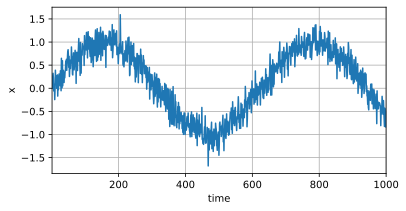

In [ ]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l


# 自己生成一组时间序列数据
T = 1000  # 总共产生1000个点
time = torch.arange(1, T + 1, dtype=torch.float32) # arange
x = torch.sin(0.01 * time) + torch.normal(0, 0.2, (T,))
d2l.plot(time, [x], 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

- `torch.normal(0, 0.2, (T,))`： 随机噪声。均值为0，标准差为0.2，形状为（1000，）

In [ ]:
# 把连续数据变成训练样本
# 把一条连续的时间序列 x，切割成很多组训练数据。
# 每组用前 4 个数作为输入，第 5 个数作为正确答案。
tau =4 # 我们希望模型根据过去4个时间点的数据，预测下一个时间点
features = torch.zeros((T -tau ,tau)) # 每组输入需要tau个数
for i in range(tau):
    features[:,i] = x[i: T-tau+i]
labels = x[tau:].reshape((-1,1))

batch_size, n_train =16,600
train_iter = d2l.load_array((features[:n_train], labels[:n_train]),
                            batch_size, is_train=True)

- `features` 是模型的输入。
- `labels` 是模型应该预测出来的正确答案

In [4]:
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)


def get_net():
    net = nn.Sequential(nn.Linear(4,10),
                        nn.ReLU(),
                        nn.Linear(10,1))
    net.apply(init_weights)
    return net

loss = nn.MSELoss(reduction='none')

In [5]:
def train(net, train_iter, loss, epochs, lr):
    trainer = torch.optim.Adam(net.parameters(), lr)
    for epoch in range(epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.sum().backward()
            trainer.step()
        print(f'epoch {epoch + 1}, '
              f'loss: {d2l.evaluate_loss(net, train_iter, loss):f}')

net = get_net()
train(net, train_iter, loss, 5, 0.01)

epoch 1, loss: 0.091446
epoch 2, loss: 0.065458
epoch 3, loss: 0.056506
epoch 4, loss: 0.053868
epoch 5, loss: 0.052391


/home/beichen/anaconda3/envs/xinjiali_env/lib/python3.11/site-packages/d2l/torch.py:3179: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  self.data = [a + float(b) for a, b in zip(self.data, args)]


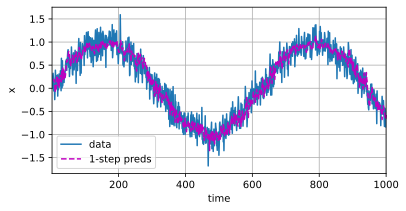

In [6]:
onestep_preds = net(features)
d2l.plot([time, time[tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy()], 'time',
         'x', legend=['data', '1-step preds'], xlim=[1, 1000],
         figsize=(6, 3))

- 一步预测
  - 输入 10, 20, 30, 40 → 预测 51
  - 输入 20, 30, 40, 50 → 预测 59
  - 第二次预测仍然使用真实的 50，没有使用第一次预测的 51。这就是一步预测。

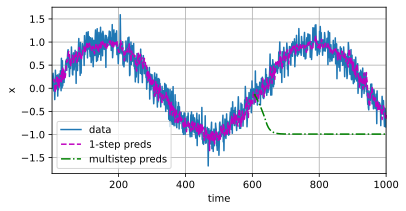

In [7]:
multistep_preds = torch.zeros(T)
multistep_preds[: n_train + tau] = x[: n_train + tau]
for i in range(n_train + tau, T):
    multistep_preds[i] = net(
        multistep_preds[i - tau:i].reshape((1, -1)))

d2l.plot([time, time[tau:], time[n_train + tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy(),
          multistep_preds[n_train + tau:].detach().numpy()], 'time',
         'x', legend=['data', '1-step preds', 'multistep preds'],
         xlim=[1, 1000], figsize=(6, 3))

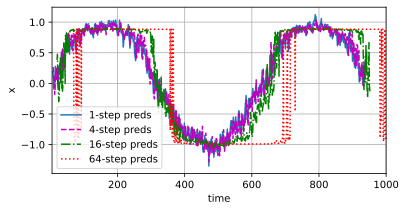

In [8]:
max_steps = 64

features = torch.zeros((T - tau - max_steps + 1, tau + max_steps))
# 列i（i<tau）是来自x的观测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau):
    features[:, i] = x[i: i + T - tau - max_steps + 1]

# 列i（i>=tau）是来自（i-tau+1）步的预测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau, tau + max_steps):
    features[:, i] = net(features[:, i - tau:i]).reshape(-1)

steps = (1, 4, 16, 64)
d2l.plot([time[tau + i - 1: T - max_steps + i] for i in steps],
         [features[:, (tau + i - 1)].detach().numpy() for i in steps], 'time', 'x',
         legend=[f'{i}-step preds' for i in steps], xlim=[5, 1000],
         figsize=(6, 3))